#### Phase 1: Loading Raw Data

##### imports

In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import kagglehub as kg
from kagglehub import KaggleDatasetAdapter
import os

###### JSON Path

In [70]:
LOCAL_JSON_PATH = '../data/raw/raw_pokemon.json'

In [71]:
# The code in this cell checks if the data has already been downloaded and saved under the name raw_pokemon.json.
# If the data hasn't been found, it will be downloaded from Kaggle

if not os.path.exists(LOCAL_JSON_PATH):
    print("Local file not found. Downloading from Kaggle.")
    
    # 1. Define the exact columns we want to keep
    columns_to_keep = ['Number', ' Name', ' Type1', ' Type2', ' Base_Total', ' HP', ' Attack', ' Defense', ' Evolutions', 'Legendary']

    
    # 1. Download from Kaggle and turn it into a DataFrame
    df = kg.load_dataset(
        KaggleDatasetAdapter.PANDAS,
        "dizzypanda/gen-1-pokemon",
        "FirstGenPokemon.csv",
        pandas_kwargs= {'usecols': columns_to_keep}
    )
    
    # 2. Convert downloaded file from CSV to JSON format
    pokemon_data = df.to_dict(orient='records')
    
    # 3. Removing any leading or trailing spaces to avoid confusion later on
    # df.columns = df.columns.str.strip()
    
    # 4. Save to our local folder
    os.makedirs('../data/raw', exist_ok=True) # Creates the folders if they don't exist yet
    with open(LOCAL_JSON_PATH, 'w', encoding='utf-8') as f:
        json.dump(pokemon_data, f, indent=4)
        
    print(f"Download complete. Saved locally to {LOCAL_JSON_PATH}")
else:
    print("Local file Kaggle file found.")

# 5. read the downloaded file
df = pd.read_json(LOCAL_JSON_PATH)

# check to see if column names have leading and trailing empty spaces
# print(df.columns.tolist())

print("\nData is ready for processing")
print(f"Shape: {df.shape}")
df.head()

Local file Kaggle file found.

Data is ready for processing
Shape: (152, 10)


,Number,Name,Type1,Type2,Base_Total,HP,Attack,Defense,Evolutions,Legendary
0,1,Bulbasaur,GRASS,poison,253,45,49,49,2,0
1,2,Ivysaur,grass,poison,325,60,62,63,2,0
2,3,Venusaur,grass,poison,425,80,82,83,2,0
3,4,Charmander,fire,NaN,249,39,52,43,2,0
4,5,Charmeleon,fire,NaN,325,58,64,58,2,0


#### Phase 2: Data Profiling

In [72]:
# Structure Check
print(df.info())

# Checking for missing values
missing_values = df.isna().sum()
print(f"Amount of missing values: \n\n{missing_values}")

# Validity and Anomaly check
type1_col = [col for col in df.columns if 'Type1' in col][0]
print(f"\n Messy formatting detected in '{type1_col}':")
print(df[type1_col].unique()) # This displays all unique typings in Column 'Type1'

print(f"\n Duplicate rows check: {df.duplicated().sum()} found")

<class 'pandas.DataFrame'>
RangeIndex: 152 entries, 0 to 151
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Number        152 non-null    int64 
 1    Name         152 non-null    str   
 2    Type1        151 non-null    str   
 3    Type2        62 non-null     str   
 4    Base_Total   152 non-null    int64 
 5    HP           152 non-null    object
 6    Attack       152 non-null    int64 
 7    Defense      152 non-null    int64 
 8    Evolutions   152 non-null    int64 
 9   Legendary     152 non-null    object
dtypes: int64(5), object(2), str(3)
memory usage: 12.0+ KB
None
Amount of missing values: 

Number           0
 Name            0
 Type1           1
 Type2          90
 Base_Total      0
 HP              0
 Attack          0
 Defense         0
 Evolutions      0
Legendary        0
dtype: int64

 Messy formatting detected in ' Type1 ':
<StringArray>
[   'GRASS ',    'grass ',     'fire ',    'water '

#### Phase 3: Data Quality Rules (The Contract) and Data Mapping
Based on the profiling above, the following transformation rules will be applied and documented for the Data Engineering team:
1. **Structure:** Strip all leading/trailing whitespace from column names.
2. **Standardization:** Strip whitespace and apply Title Case to all `Type` columns (e.g., `"GRASS "` → `"Grass"`).
3. **Completeness:** Fill missing `Type2` values with `"None"` (since many Pokémon are single-type).
4. **Validity:** Ensure all stat columns (`HP`, `Attack`, `Defense`, `Base_Total`) are strictly numeric.
5. **Uniqueness:** Drop any duplicate Pokémon entries based on `Name`.

In [73]:
# 1. Define the Source-to-Target Mapping Contract
data_contract = {
    "dataset": "gen1_pokemon",
    "steward": "Dwayne Kruydenhof",
    "rules": {
        "column_names": "Strip leading/trailing whitespace from all headers.",
        "categorical_formatting": "Strip whitespace and apply .str.title() to Type1 and Type2.",
        "missing_values": "Fill NaN in Type2 with 'None'.",
        "data_types": "Enforce numeric types on HP, Attack, Defense, Base_Total, and Evolutions.",
        "deduplication": "Drop duplicates based on the 'Name' column."
    },
    "mappings": [
        {"source": " Number ", "target": "Number", "type": "int"},
        {"source": " Name ", "target": "Name", "type": "string"},
        {"source": " Type1 ", "target": "Type1", "type": "string"},
        {"source": " Type2 ", "target": "Type2", "type": "string"},
        {"source": " Base_Total ", "target": "Base_Total", "type": "int"},
        {"source": " HP ", "target": "HP", "type": "int"},
        {"source": " Attack ", "target": "Attack", "type": "int"},
        {"source": " Defense ", "target": "Defense", "type": "int"},
        {"source": " Evolutions ", "target": "Evolutions", "type": "int"},
        {"source": "Legendary ", "target": "Legendary", "type": "int"}
    ]
}

# 2. Save the contract to the outputs folder
os.makedirs('../outputs', exist_ok=True)
with open('../outputs/data_contract.json', 'w', encoding='utf-8') as f:
    json.dump(data_contract, f, indent=4)

print("Data Contract saved to '../outputs/data_contract.json'")

Data Contract saved to '../outputs/data_contract.json'


#### Phase 4: Data Cleaning & Transformation
Applying the rules defined in the Data Contract to produce a clean, analysis-ready DataFrame.

In [74]:
# If you're going to edit the data within a dataset, work with a copy of it
df_clean = df.copy()

# Strip all whitespaces from column names to avoid error related to the spelling of the column names
df_clean.columns = df_clean.columns.str.strip()

# Rule 2 & 3: Standardize Type columns (remove rows with empty Type1, strip spaces, title case, fill NaN)
df_clean['Type1'] = df_clean['Type1'].str.strip().str.title().dropna()
df_clean['Type2'] = df_clean['Type2'].str.strip().str.title().fillna('None')

# Rule 4: Ensure numeric columns are actually numeric (coerce errors to NaN, then we can check)
numeric_values = ['Number', 'Base_Total', 'HP', 'Attack', 'Defense', 'Evolutions', 'Legendary']
for col in numeric_values:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# Rule 5: Drop duplicates based on Name
df_clean = df_clean.drop_duplicates(subset=['Name']).reset_index(drop=True)


#### Phase 4: Statistical Analysis & Visualization (Professor Oak's Requests)
Generating actionable insights for the Kanto Region Ecological Summit.

Charts have been generated and saved to '../outputs/summit_charts.png'


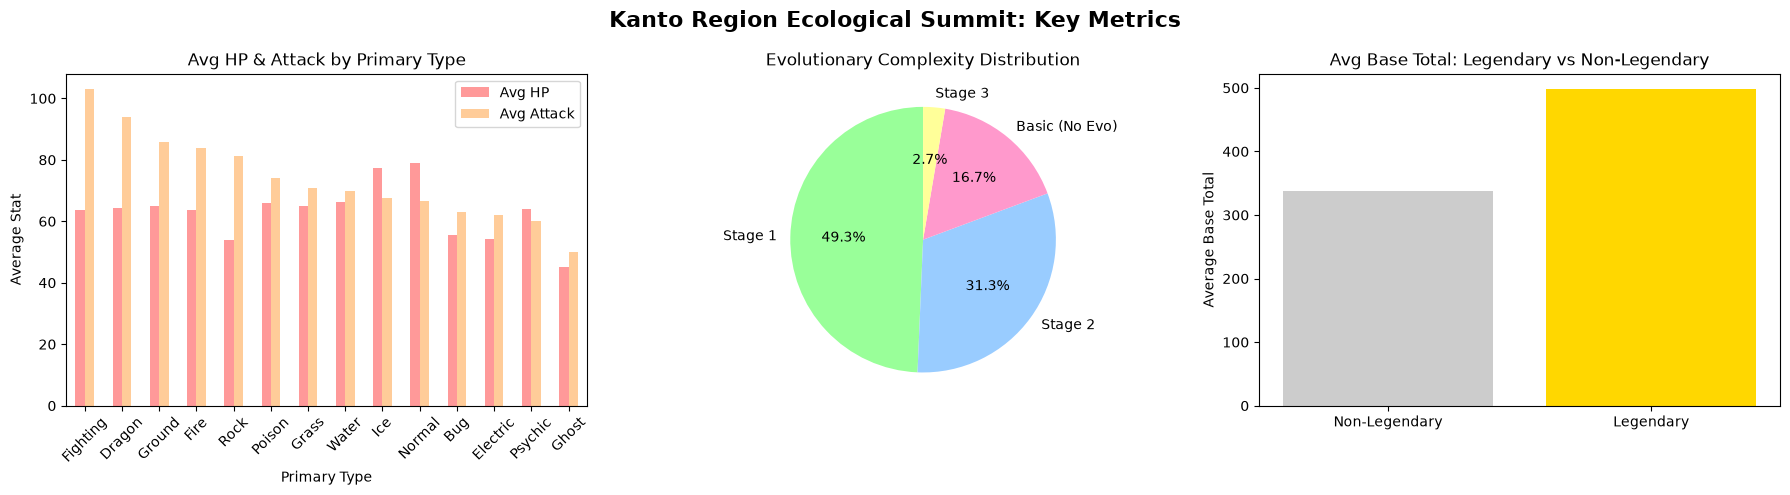

In [75]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Kanto Region Ecological Summit: Key Metrics', fontsize=16, fontweight='bold')

# --- Chart 1: Type Dominance (Avg HP and Attack by Type1) ---
type_stats = df_clean.groupby('Type1')[['HP', 'Attack']].mean().round(1).sort_values('Attack', ascending=False)
type_stats.plot(kind='bar', ax=axes[0], color=['#ff9999', '#ffcc99'])
axes[0].set_title('Avg HP & Attack by Primary Type')
axes[0].set_xlabel('Primary Type')
axes[0].set_ylabel('Average Stat')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(['Avg HP', 'Avg Attack'])

# --- Chart 2: Evolutionary Complexity ---
# Map evolutions to readable categories
evo_map = {0: 'Basic (No Evo)', 1: 'Stage 1', 2: 'Stage 2', 3: 'Stage 3'}
df_clean['Evo_Category'] = df_clean['Evolutions'].map(evo_map)
evo_counts = df_clean['Evo_Category'].value_counts()
axes[1].pie(evo_counts, labels=evo_counts.index, autopct='%1.1f%%', startangle=90, colors=['#99ff99', '#99ccff', '#ff99cc', '#ffff99'])
axes[1].set_title('Evolutionary Complexity Distribution')

# Chart 3: Legendary Distribution
legendary_stats = df_clean.groupby('Legendary')['Base_Total'].mean().round(1)
legendary_labels = ['Non-Legendary', 'Legendary']
axes[2].bar(legendary_labels, legendary_stats.values, color=['#cccccc', '#ffd700'])
axes[2].set_title('Avg Base Total: Legendary vs Non-Legendary')
axes[2].set_ylabel('Average Base Total')

plt.tight_layout()

# Save the chart to the outputs folder
plt.savefig('../outputs/summit_charts.png', dpi=600, bbox_inches='tight')
print("Charts have been generated and saved to '../outputs/summit_charts.png'")

plt.show()
